# Adaptive Threshold — Implementation

## Mục tiêu
1. Cài đặt Integral Image.
2. Cài đặt Bradley–Roth và Sauvola.
3. So sánh với ngưỡng thủ công và Otsu.
4. Khảo sát ảnh hưởng của tham số radius, t và k.
5. Đo thời gian chạy theo radius.

Import thư viện

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
from pathlib import Path

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Môi trường đã sẵn sàng!")

OpenCV: 5.0.0
NumPy: 2.4.6
Môi trường đã sẵn sàng!


Đọc ảnh

Kích thước ảnh (H, W): (2000, 3000)
Kiểu dữ liệu: uint8
Độ sáng trung bình: 71.49


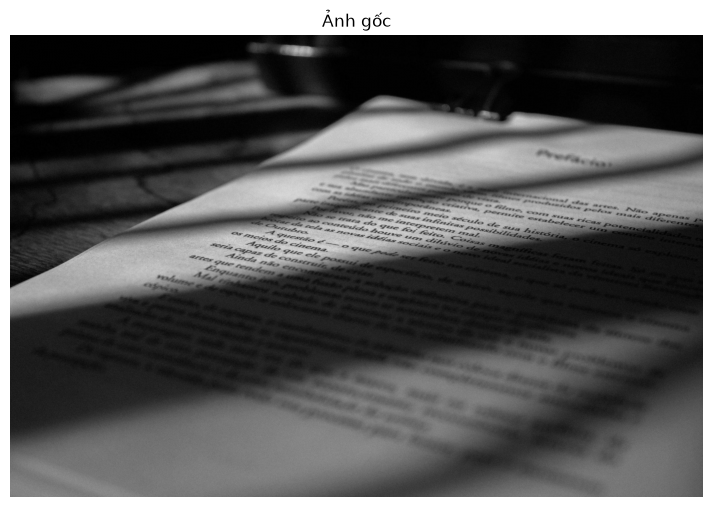

In [3]:
image_path = Path("images/input.jpg")

img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        f"Không đọc được ảnh: {image_path.resolve()}"
    )

img = img.astype(np.uint8)

print("Kích thước ảnh (H, W):", img.shape)
print("Kiểu dữ liệu:", img.dtype)
print("Độ sáng trung bình:", round(float(img.mean()), 2))

plt.figure(figsize=(10, 6))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Ảnh gốc")
plt.axis("off")
plt.show()

Cài đặt ảnh tích phân

In [4]:
def integral_image(img):
    """
    Trả về ảnh tích phân kích thước (H+1, W+1),
    kiểu int64, hàng đầu và cột đầu bằng 0.
    """
    img = np.asarray(img)

    if img.ndim != 2:
        raise ValueError("Ảnh phải là ma trận 2 chiều.")

    S = np.zeros(
        (img.shape[0] + 1, img.shape[1] + 1),
        dtype=np.int64
    )

    S[1:, 1:] = np.cumsum(
        np.cumsum(img.astype(np.int64), axis=0),
        axis=1
    )

    return S


def box_sum(S, y1, x1, y2, x2):
    """
    Tổng vùng [y1:y2, x1:x2] theo tọa độ ảnh gốc.
    y2 và x2 không nằm trong vùng (exclusive).
    """
    return (
        S[y2, x2]
        - S[y1, x2]
        - S[y2, x1]
        + S[y1, x1]
    )


S = integral_image(img)

print("Kích thước ảnh gốc:", img.shape)
print("Kích thước ảnh tích phân:", S.shape)
print("Kiểu dữ liệu:", S.dtype)
print("Hàng đầu toàn 0:", np.all(S[0, :] == 0))
print("Cột đầu toàn 0:", np.all(S[:, 0] == 0))

Kích thước ảnh gốc: (2000, 3000)
Kích thước ảnh tích phân: (2001, 3001)
Kiểu dữ liệu: int64
Hàng đầu toàn 0: True
Cột đầu toàn 0: True


In [5]:
y1, x1, y2, x2 = 0, 0, min(10, img.shape[0]), min(10, img.shape[1])

sum_integral = box_sum(S, y1, x1, y2, x2)
sum_direct = img[y1:y2, x1:x2].astype(np.int64).sum()

print("Tổng từ ảnh tích phân:", sum_integral)
print("Tổng cộng trực tiếp:", sum_direct)
assert sum_integral == sum_direct
print("Kiểm tra box_sum: PASS")

Tổng từ ảnh tích phân: 160
Tổng cộng trực tiếp: 160
Kiểm tra box_sum: PASS


Tính trung bình và độ lệch chuẩn cục bộ

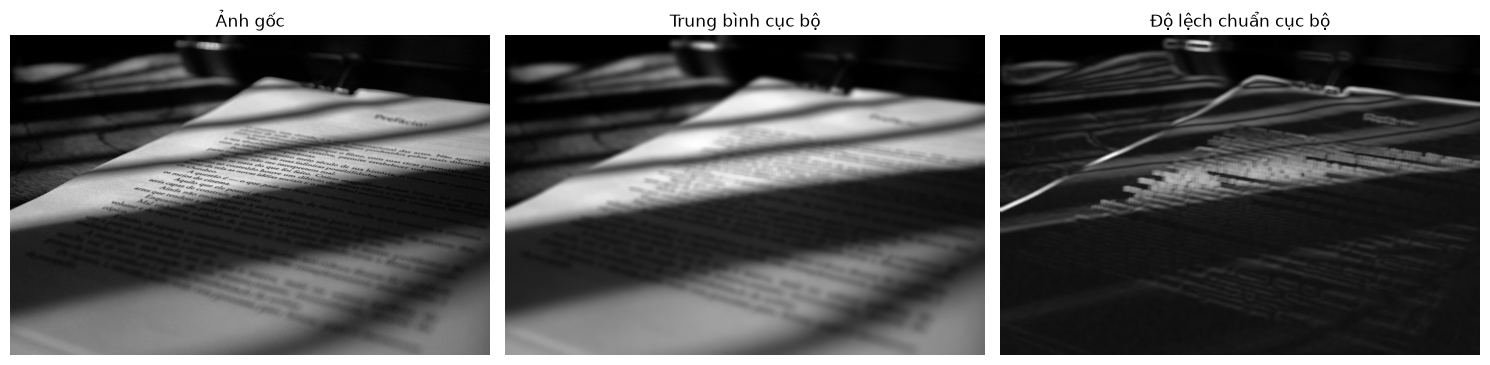

In [6]:
def local_mean_std(img, radius):
    """
    Tính trung bình và độ lệch chuẩn cục bộ.
    Cửa sổ được cắt tại biên ảnh.
    """
    if radius < 1:
        raise ValueError("radius phải >= 1")

    a = img.astype(np.float64)
    H, W = a.shape

    S1 = integral_image(a.astype(np.int64))
    S2 = integral_image(np.rint(a * a).astype(np.int64))

    ys = np.arange(H)
    xs = np.arange(W)

    y0 = np.maximum(ys - radius, 0)
    y1 = np.minimum(ys + radius + 1, H)
    x0 = np.maximum(xs - radius, 0)
    x1 = np.minimum(xs + radius + 1, W)

    # Mỗi vị trí được xác định bằng bốn tọa độ biên
    total = (
        S1[y1[:, None], x1[None, :]]
        - S1[y0[:, None], x1[None, :]]
        - S1[y1[:, None], x0[None, :]]
        + S1[y0[:, None], x0[None, :]]
    )

    total_sq = (
        S2[y1[:, None], x1[None, :]]
        - S2[y0[:, None], x1[None, :]]
        - S2[y1[:, None], x0[None, :]]
        + S2[y0[:, None], x0[None, :]]
    )

    area = (
        (y1 - y0)[:, None]
        * (x1 - x0)[None, :]
    )

    mean = total / area
    variance = np.maximum(total_sq / area - mean**2, 0)
    std = np.sqrt(variance)

    return mean, std


mean_local, std_local = local_mean_std(img, radius=15)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Ảnh gốc")

axes[1].imshow(mean_local, cmap="gray")
axes[1].set_title("Trung bình cục bộ")

axes[2].imshow(std_local, cmap="gray")
axes[2].set_title("Độ lệch chuẩn cục bộ")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Cài đặt Bradley–Roth

ngưỡng Bradley–Roth là:
\[
T(x,y)=m(x,y)(1-t)
\]

Trong đó \(m(x,y)\) là trung bình cục bộ, còn \(t\) là tham số điều chỉnh ngưỡng.

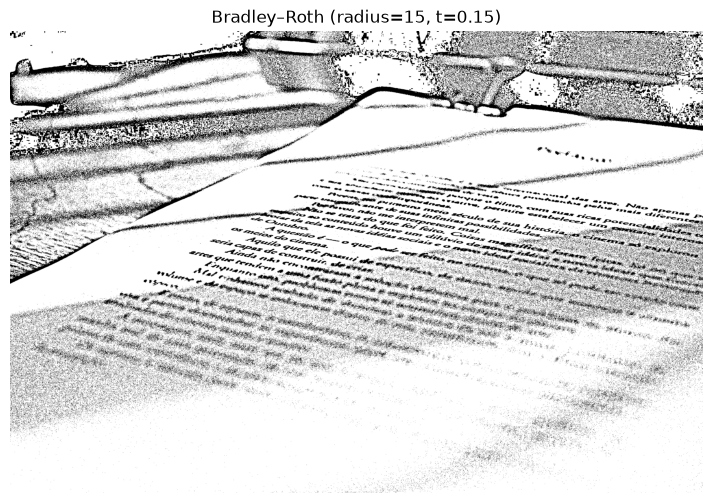

In [7]:
def adaptive_threshold_bradley(img, radius=15, t=0.15):
    mean, _ = local_mean_std(img, radius)
    threshold = mean * (1 - t)

    # Pixel tối hơn ngưỡng là chữ (đen), còn lại là nền (trắng)
    binary = np.where(img <= threshold, 0, 255).astype(np.uint8)

    return binary


bradley = adaptive_threshold_bradley(
    img,
    radius=15,
    t=0.15
)

plt.figure(figsize=(10, 6))
plt.imshow(bradley, cmap="gray", vmin=0, vmax=255)
plt.title("Bradley–Roth (radius=15, t=0.15)")
plt.axis("off")
plt.show()


Cài đặt Sauvola

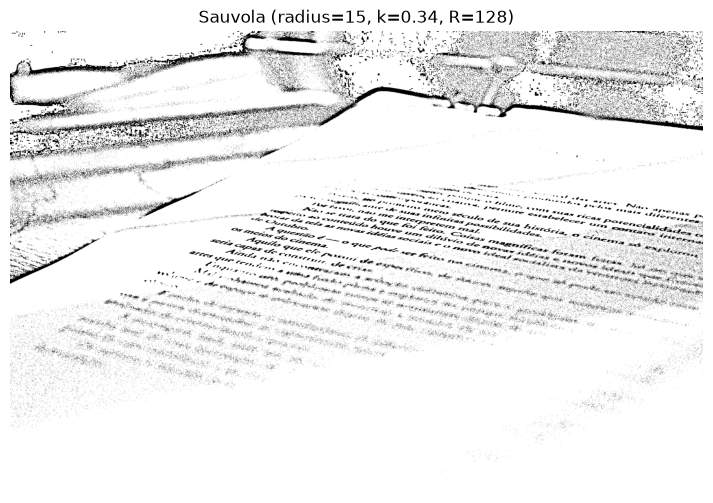

In [8]:
def adaptive_threshold_sauvola_custom(
    img, radius=15, k=0.34, R=128
):
    mean, std = local_mean_std(img, radius)

    threshold = mean * (
        1 + k * (std / R - 1)
    )

    binary = np.where(img <= threshold, 0, 255).astype(np.uint8)

    return binary


sauvola = adaptive_threshold_sauvola_custom(
    img,
    radius=15,
    k=0.34,
    R=128
)

plt.figure(figsize=(10, 6))
plt.imshow(sauvola, cmap="gray", vmin=0, vmax=255)
plt.title("Sauvola (radius=15, k=0.34, R=128)")
plt.axis("off")
plt.show()

So sánh bốn phương pháp

Chạy bốn phương pháp trên cùng một ảnh:
1. Ngưỡng thủ công — lấy giá trị 127 làm ngưỡng.
2. Otsu — tự tìm ngưỡng toàn cục.
3. Bradley–Roth — ngưỡng dựa trên trung bình cục bộ.
4. Sauvola — ngưỡng dựa trên trung bình và độ lệch chuẩn cục bộ.

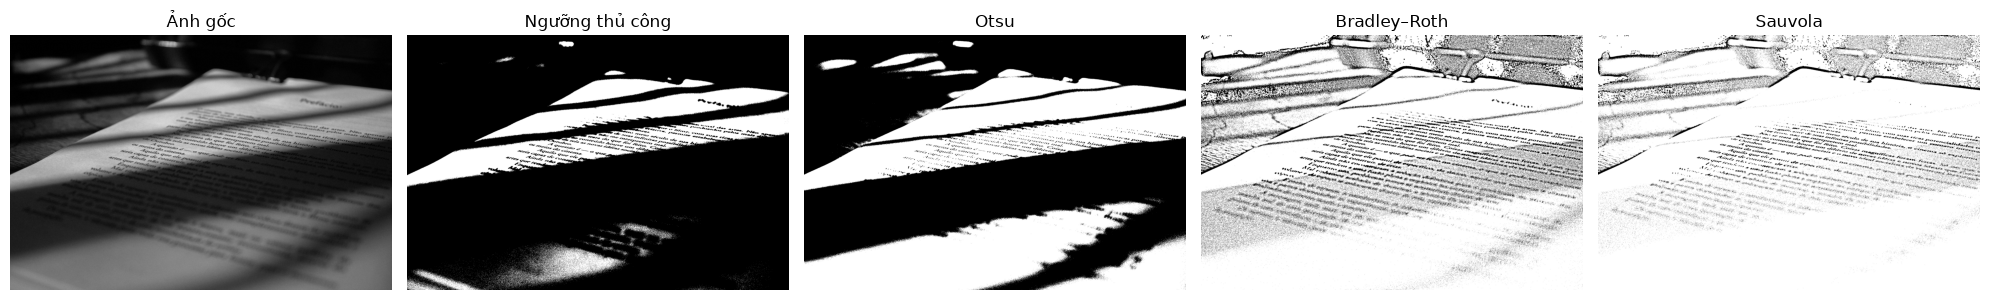

Ngưỡng Otsu tìm được: 80.0


In [9]:
# 1. Ngưỡng thủ công
_, manual = cv2.threshold(
    img, 127, 255, cv2.THRESH_BINARY
)

# 2. Otsu
otsu_threshold, otsu = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 3. Bradley–Roth
bradley = adaptive_threshold_bradley(
    img, radius=15, t=0.15
)

# 4. Sauvola
sauvola = adaptive_threshold_sauvola_custom(
    img, radius=15, k=0.34, R=128
)

results = [
    ("Ảnh gốc", img),
    ("Ngưỡng thủ công", manual),
    ("Otsu", otsu),
    ("Bradley–Roth", bradley),
    ("Sauvola", sauvola),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for ax, (title, image) in zip(axes, results):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ngưỡng Otsu tìm được:", otsu_threshold)

thay đổi tham số

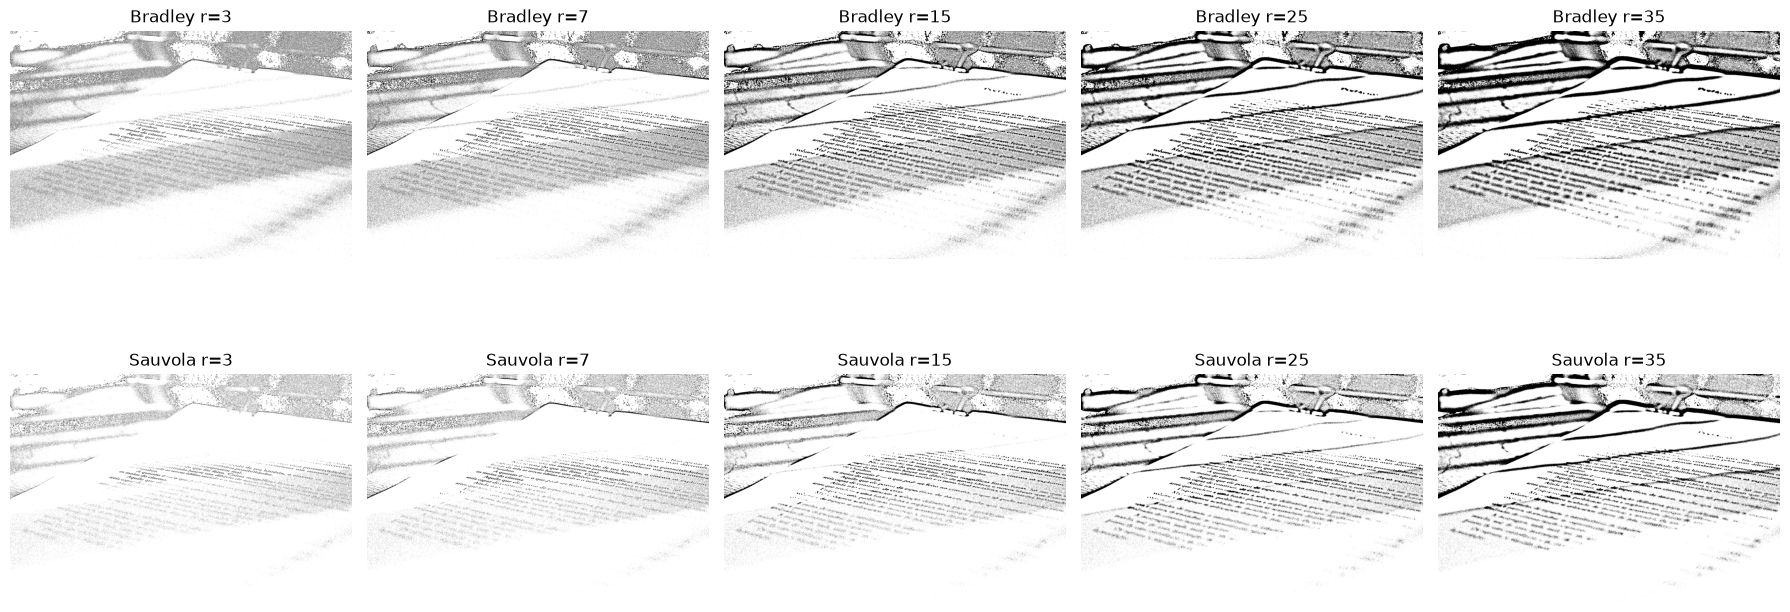

In [10]:
radii = [3, 7, 15, 25, 35]

fig, axes = plt.subplots(
    2, len(radii),
    figsize=(18, 8)
)

for i, r in enumerate(radii):
    b = adaptive_threshold_bradley(img, radius=r, t=0.15)
    s = adaptive_threshold_sauvola_custom(
        img, radius=r, k=0.34, R=128
    )

    axes[0, i].imshow(b, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(f"Bradley r={r}")
    axes[0, i].axis("off")

    axes[1, i].imshow(s, cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title(f"Sauvola r={r}")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Bradley–Roth")
axes[1, 0].set_ylabel("Sauvola")

plt.tight_layout()
plt.show()

Tiếp tục thử t và k

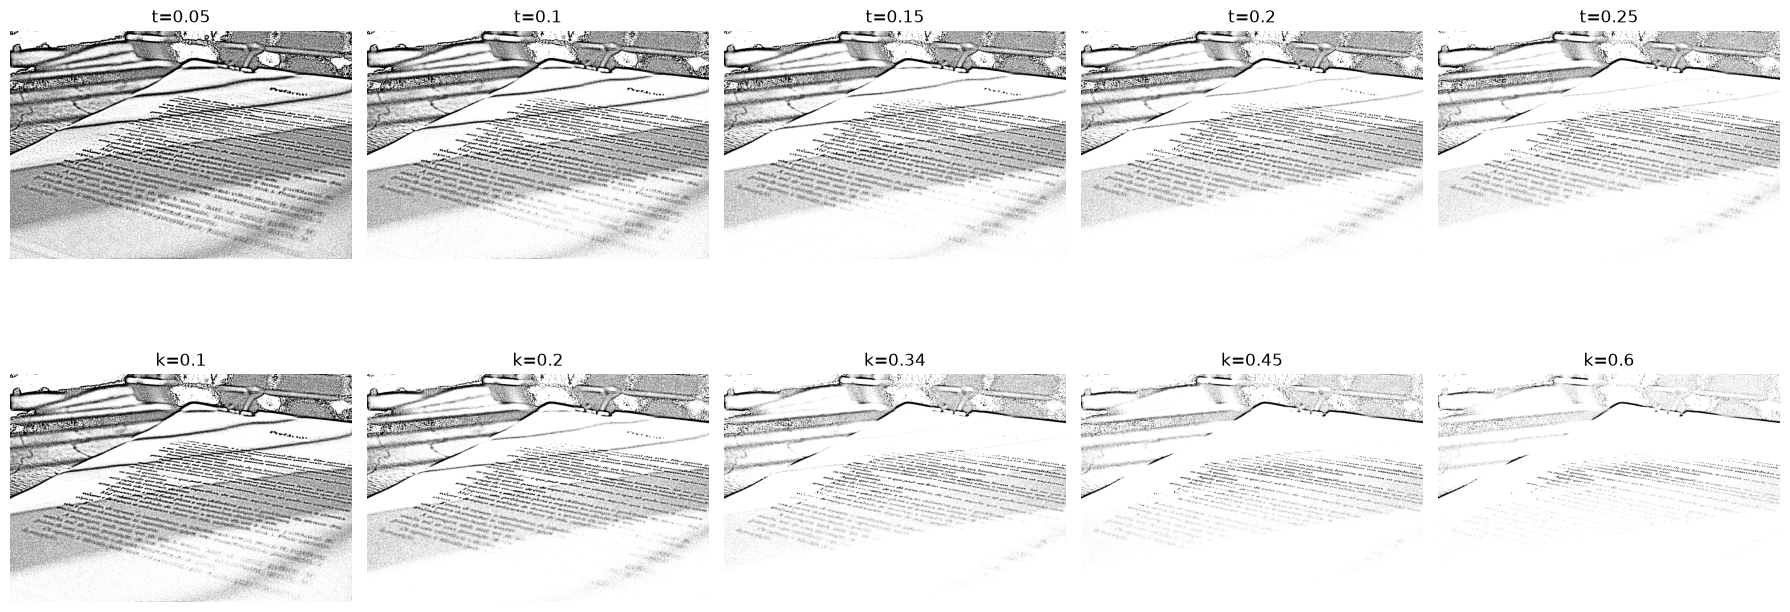

In [11]:
t_values = [0.05, 0.10, 0.15, 0.20, 0.25]
k_values = [0.10, 0.20, 0.34, 0.45, 0.60]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, t in enumerate(t_values):
    out = adaptive_threshold_bradley(
        img, radius=15, t=t
    )
    axes[0, i].imshow(out, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(f"t={t}")
    axes[0, i].axis("off")

for i, k in enumerate(k_values):
    out = adaptive_threshold_sauvola_custom(
        img, radius=15, k=k, R=128
    )
    axes[1, i].imshow(out, cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title(f"k={k}")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Bradley–Roth")
axes[1, 0].set_ylabel("Sauvola")

plt.tight_layout()
plt.show()

Đo thời gian theo radius

In [12]:
def benchmark(func, repeats=3):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        func()
        times.append(time.perf_counter() - start)

    return float(np.median(times))


radii_time = [1, 2, 4, 8, 16, 32, 64]
timing_bradley = []
timing_sauvola = []
timing_box = []
timing_separable = []

# Dùng ảnh thu nhỏ để thời gian chạy trực tiếp
# không quá lâu. Tăng kích thước nếu máy chạy tốt.
scale = min(1.0, 600 / max(img.shape))
small = cv2.resize(
    img,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_AREA
) if scale < 1 else img.copy()

small_f = small.astype(np.float32)

for r in radii_time:
    timing_bradley.append(
        benchmark(
            lambda r=r: adaptive_threshold_bradley(
                small, radius=r, t=0.15
            ),
            repeats=3
        )
    )

    timing_sauvola.append(
        benchmark(
            lambda r=r: adaptive_threshold_sauvola_custom(
                small, radius=r, k=0.34, R=128
            ),
            repeats=3
        )
    )

    # Tham chiếu: lọc trung bình hộp trực tiếp bằng OpenCV
    timing_box.append(
        benchmark(
            lambda r=r: cv2.boxFilter(
                small_f, -1, (2*r + 1, 2*r + 1),
                normalize=True,
                borderType=cv2.BORDER_REPLICATE
            ),
            repeats=3
        )
    )

    # Tham chiếu: lọc hộp tách thành hai chiều
    timing_separable.append(
        benchmark(
            lambda r=r: cv2.sepFilter2D(
                small_f, -1,
                np.ones(2*r + 1, np.float32) / (2*r + 1),
                np.ones(2*r + 1, np.float32) / (2*r + 1),
                borderType=cv2.BORDER_REPLICATE
            ),
            repeats=3
        )
    )

print("Benchmark hoàn tất.")
print("Kích thước ảnh đo:", small.shape)

Benchmark hoàn tất.
Kích thước ảnh đo: (400, 600)


Vẽ biểu đồ

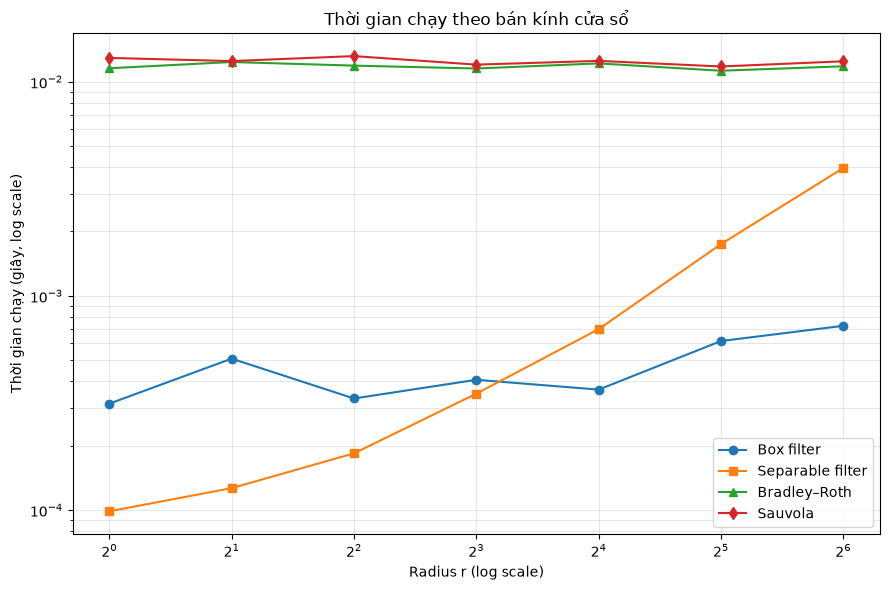

In [13]:
plt.figure(figsize=(9, 6))

plt.plot(radii_time, timing_box, marker="o", label="Box filter")
plt.plot(radii_time, timing_separable, marker="s", label="Separable filter")
plt.plot(radii_time, timing_bradley, marker="^", label="Bradley–Roth")
plt.plot(radii_time, timing_sauvola, marker="d", label="Sauvola")

plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("Radius r (log scale)")
plt.ylabel("Thời gian chạy (giây, log scale)")
plt.title("Thời gian chạy theo bán kính cửa sổ")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
from pathlib import Path
import pandas as pd
from IPython.display import display

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

cv2.imwrite(str(output_dir / "original.png"), img)
cv2.imwrite(str(output_dir / "manual.png"), manual)
cv2.imwrite(str(output_dir / "otsu.png"), otsu)
cv2.imwrite(str(output_dir / "bradley_roth.png"), bradley)
cv2.imwrite(str(output_dir / "sauvola.png"), sauvola)

timing_df = pd.DataFrame({
    "radius": radii_time,
    "box_filter_s": timing_box,
    "separable_filter_s": timing_separable,
    "bradley_roth_s": timing_bradley,
    "sauvola_s": timing_sauvola
})

timing_df.to_csv(
    output_dir / "timing.csv",
    index=False
)

print("Đã lưu kết quả vào:", output_dir.resolve())
display(timing_df)


Đã lưu kết quả vào: D:\b2-lap1\AdaptiveThreshold\output


,radius,box_filter_s,separable_filter_s,bradley_roth_s,sauvola_s
0,1,0.000314,0.000099,0.011563,0.012925
1,2,0.000510,0.000127,0.012367,0.012491
2,4,0.000332,0.000184,0.011896,0.013179
3,8,0.000406,0.000350,0.011534,0.012024
4,16,0.000365,0.000700,0.012181,0.012518
5,32,0.000616,0.001746,0.011260,0.011785
6,64,0.000726,0.003957,0.011810,0.012464
